# Walkthrough: Pearson-Korrelation

Schritt-für-Schritt-Beispiel aus der Case Study: SQL-Abfrage → Dataframe (Land × Metrik) → Korrelationsmatrix → Heatmap.

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 

In [4]:
from bina_db import connect

maria_db_connection = connect()

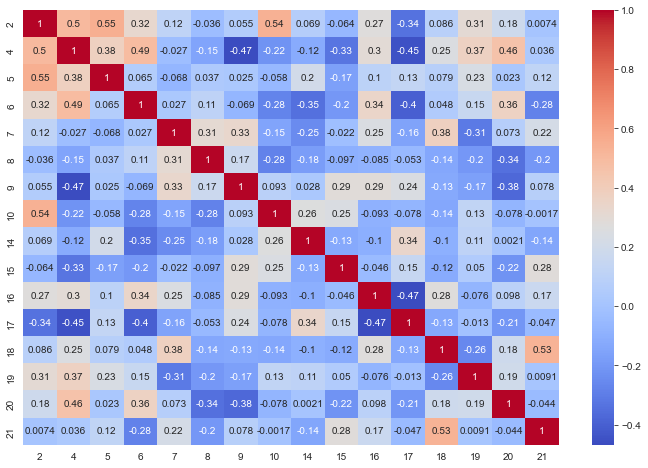

,2,4,5,6,7,8,9,10,14,15,16,17,18,19,20,21
2,1.000000,0.503297,0.547726,0.324075,0.115805,-0.036269,0.054978,0.537326,0.068802,-0.064219,0.272590,-0.340159,0.085599,0.305291,0.181167,0.007409
4,0.503297,1.000000,0.377524,0.490555,-0.027195,-0.152343,-0.468504,-0.219454,-0.121764,-0.325461,0.298961,-0.450831,0.248576,0.371952,0.455345,0.035941
5,0.547726,0.377524,1.000000,0.064886,-0.068267,0.037166,0.025323,-0.058454,0.196919,-0.169923,0.100105,0.131761,0.078970,0.231828,0.023317,0.118099
6,0.324075,0.490555,0.064886,1.000000,0.026681,0.107197,-0.069145,-0.277501,-0.347006,-0.201583,0.341703,-0.400276,0.048399,0.151905,0.364093,-0.282684
7,0.115805,-0.027195,-0.068267,0.026681,1.000000,0.306641,0.334053,-0.149330,-0.247546,-0.022222,0.246288,-0.158085,0.378891,-0.313564,0.072523,0.215941
8,-0.036269,-0.152343,0.037166,0.107197,0.306641,1.000000,0.171626,-0.282794,-0.181018,-0.097207,-0.085453,-0.053042,-0.140788,-0.202580,-0.344361,-0.199435
9,0.054978,-0.468504,0.025323,-0.069145,0.334053,0.171626,1.000000,0.092681,0.027531,0.285497,0.285354,0.242975,-0.125506,-0.169930,-0.376205,0.077678
10,0.537326,-0.219454,-0.058454,-0.277501,-0.149330,-0.282794,0.092681,1.000000,0.263696,0.245430,-0.093390,-0.078210,-0.139576,0.125354,-0.077952,-0.001691
14,0.068802,-0.121764,0.196919,-0.347006,-0.247546,-0.181018,0.027531,0.263696,1.000000,-0.128958,-0.102543,0.339399,-0.100535,0.108548,0.002149,-0.144732
15,-0.064219,-0.325461,-0.169923,-0.201583,-0.022222,-0.097207,0.285497,0.245430,-0.128958,1.000000,-0.046025,0.150709,-0.122849,0.050242,-0.216402,0.282364


In [7]:
sql_query = ("select country, metric_definition, metric.value from metric join country on metric.country = country.id where year = 2015 and country in (1, 3, 4, 7, 11, 12, 14, 15, 16, 18, 19, 21, 22, 24, 26, 27, 29, 30, 32, 35, 36, 37, 39, 40, 41, 43, 44, 45, 46, 49, 50, 51, 54, 56, 59, 60, 61, 62, 64, 65, 66, 67, 70, 72, 76, 77, 81, 83, 84, 85, 87, 92, 94, 97, 100, 101, 102, 103, 104, 105, 106, 107, 108, 110, 111, 112, 113, 115, 116, 117, 120, 121, 122, 123, 124, 125, 126, 127, 128, 130, 131, 133, 134, 135, 137, 138, 141, 142, 144, 146, 148, 149, 151, 152, 153, 156, 157, 159, 160, 161, 162, 165, 167, 168, 169, 171, 172, 174, 175, 176, 178, 179, 181, 183, 184, 185, 196, 197, 198, 200, 201, 203, 204, 206, 207, 210, 211, 212, 213, 215, 216, 217, 218, 219, 220, 221, 223, 226, 227, 228, 229, 232, 233, 234, 235, 236, 238, 239, 241, 242, 247, 248, 249, 250) and metric_definition not in (1, 3) and country.region = 'Africa'")
sql_data = pd.read_sql(sql_query, maria_db_connection)

unique_metric_definition_ids = sql_data["metric_definition"].unique()
count_unique_metric_definition_ids = len(unique_metric_definition_ids)

unique_country_ids = sql_data["country"].unique()
count_countries = len(unique_country_ids)

columns = ["country"] + unique_metric_definition_ids.tolist()
df = pd.DataFrame(index=range(count_countries), columns=columns)

for index, country_id in enumerate(unique_country_ids):
    df.at[index, "country"] = country_id

df.set_index("country", inplace=True)

for index, data in sql_data.iterrows():
    country_id = data["country"]
    metric_definition_id = data["metric_definition"]
    metric_value = data["value"]

    df.at[country_id, metric_definition_id] = metric_value

df.fillna(value=0, inplace=True)

df

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.show()

df.corr()

In [8]:
df

,2,4,5,6,7,8,9,10,14,15,16,17,18,19,20,21
country,,,,,,,,,,,,,,,,
128,5.754,1.13145,1.11862,0.70380,0.41668,0.11023,0.18295,2.09066,2170.0,-7.0400,0.000,1.870,20.8,55200000.0,72.9,0.0
4,5.605,0.93929,1.07772,0.61766,0.28579,0.17383,0.07822,2.43209,19600.0,-6.4600,0.000,2.890,48.3,380000000.0,79.4,1.0
142,5.477,1.00761,0.98521,0.70950,0.56066,0.07521,0.37744,1.76145,383.0,1.4000,2.260,-0.138,63.8,0.0,61.9,2.0
162,5.268,0.65435,0.90432,0.16007,0.34334,0.04030,0.27233,2.89319,224000.0,2.8600,0.000,4.350,34.0,689000000.0,56.6,2.0
248,5.129,0.47038,0.91612,0.29924,0.48827,0.12468,0.19591,2.63430,458000.0,6.6600,0.000,4.450,43.8,53400000.0,61.3,1.0
206,5.057,0.18847,0.95152,0.43873,0.46582,0.39928,0.50318,2.11032,63600.0,6.9000,0.000,4.680,27.2,54200000.0,0.0,1.0
151,5.013,0.73479,0.64095,0.60954,0.41691,0.08546,0.07172,2.45373,56800.0,3.1700,0.000,2.170,49.1,238000000.0,70.9,0.0
152,4.971,0.08308,1.02626,0.09131,0.34037,0.15603,0.22269,3.05137,379000.0,7.0600,0.000,4.570,42.0,94800000.0,46.6,1.0
126,4.898,0.37545,1.04103,0.07612,0.31767,0.12504,0.16388,2.79832,345.0,10.2000,0.000,2.630,42.5,0.0,53.1,2.0
